# Detecção de spam com o Spambase
**CMPINAM · Introdução ao Aprendizado de Máquina · IFSP Câmpus Campinas · ADS · 2º semestre de 2026**

**Integrantes:** João Victor de Alcantara Gimenez, Lucas Moreira Lima Prado Rodrigues, Ryan David Oliveira de Meneses

**Tarefa:** classificação binária — dado um e-mail descrito por 57 atributos numéricos, prever se é **spam (1)** ou **não spam (0)**.

**Roteiro:** 1. Base e preparação → 2. Análise exploratória → 3. Modelagem → 4. Resultados e conclusões.

In [1]:
import warnings, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, precision_recall_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

RANDOM_STATE = 42          # semente fixa para reprodutibilidade
np.random.seed(RANDOM_STATE)

## 1. Base e preparação

### 1.1 Origem da base
- **Fonte:** OpenML, dataset ID 44 (*Spambase*, criado por M. Hopkins, E. Reeber, G. Forman e J. Suermondt, Hewlett-Packard Labs, 1999; também disponível no UCI Machine Learning Repository).
- **O que cada linha representa:** um e-mail.
- **Atributos (57 preditores, todos numéricos):**
  - `word_freq_*` (48): percentual de palavras do e-mail que correspondem a uma palavra específica (ex.: *free*, *money*, *remove*).
  - `char_freq_*` (6): percentual de caracteres do e-mail que correspondem a um símbolo específico (`;`, `(`, `[`, `!`, `$`, `#`).
  - `capital_run_length_average`, `_longest`, `_total` (3): média, maior e soma dos comprimentos de sequências ininterruptas de letras maiúsculas.
- **Alvo:** `class` (1 = spam, 0 = não spam).

> Neste trabalho usamos a base completa do OpenML (4.601 e-mails), baixada pela célula abaixo e salva em `dados/spambase_openml.csv`. Como não há conjunto de teste separado, **nós mesmos reservamos 20% dos dados para teste** (seção 1.3). A célula também aceita arquivos locais `dados/train.csv` e `dados/test.csv`, caso existam.

In [2]:
DATA_DIR = Path("dados")
DATA_DIR.mkdir(exist_ok=True)

# >>> AJUSTE aqui os nomes dos arquivos fornecidos pelo professor (se houver) <<<
TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH  = DATA_DIR / "test.csv"
TARGET = "class"

def to_binary(s):
    """Converte o alvo para 0/1, aceitando '0'/'1', 'spam'/'nonspam', True/False etc."""
    s = s.astype(str).str.strip().str.lower()
    return s.map({"1": 1, "1.0": 1, "spam": 1, "true": 1, "yes": 1, "sim": 1,
                  "0": 0, "0.0": 0, "nonspam": 0, "not spam": 0, "false": 0, "no": 0, "nao": 0, "não": 0}).astype(int)

train_raw, test_raw = None, None
if TRAIN_PATH.exists():
    train_raw = pd.read_csv(TRAIN_PATH)
    if TEST_PATH.exists():
        test_raw = pd.read_csv(TEST_PATH)
    print("Arquivos locais carregados.")
else:
    from sklearn.datasets import fetch_openml
    train_raw = fetch_openml(data_id=44, as_frame=True, parser="auto").frame
    train_raw.to_csv(DATA_DIR / "spambase_openml.csv", index=False)
    print("Base baixada do OpenML (ID 44) e salva em dados/spambase_openml.csv.")

for d in (train_raw, test_raw):
    if d is not None:
        d[TARGET] = to_binary(d[TARGET])

print("Treino/base completa:", train_raw.shape, "| Teste do professor:", None if test_raw is None else test_raw.shape)
train_raw.head()

Base baixada do OpenML (ID 44) e salva em dados/spambase_openml.csv.
Treino/base completa: (4601, 58) | Teste do professor: None


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,word_freq_receive,word_freq_will,word_freq_people,word_freq_report,word_freq_addresses,word_freq_free,word_freq_business,word_freq_email,word_freq_you,word_freq_credit,word_freq_your,word_freq_font,word_freq_000,word_freq_money,word_freq_hp,word_freq_hpl,word_freq_george,word_freq_650,word_freq_lab,word_freq_labs,word_freq_telnet,word_freq_857,word_freq_data,word_freq_415,word_freq_85,word_freq_technology,word_freq_1999,word_freq_parts,word_freq_pm,word_freq_direct,word_freq_cs,word_freq_meeting,word_freq_original,word_freq_project,word_freq_re,word_freq_edu,word_freq_table,word_freq_conference,char_freq_%3B,char_freq_%28,char_freq_%5B,char_freq_%21,char_freq_%24,char_freq_%23,capital_run_length_average,capital_run_length_longest,capital_run_length_total,class
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,0.00,0.64,0.00,0.00,0.00,0.32,0.00,1.29,1.93,0.00,0.96,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,0.21,0.79,0.65,0.21,0.14,0.14,0.07,0.28,3.47,0.00,1.59,0.0,0.43,0.43,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.07,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,0.38,0.45,0.12,0.00,1.75,0.06,0.06,1.03,1.36,0.32,0.51,0.0,1.16,0.06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.06,0.0,0.0,0.12,0.0,0.06,0.06,0.0,0.0,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,0.31,0.31,0.31,0.00,0.00,0.31,0.00,0.00,3.18,0.00,0.31,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,0.31,0.31,0.31,0.00,0.00,0.31,0.00,0.00,3.18,0.00,0.31,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


### 1.2 Estrutura e tipos

In [3]:
print(train_raw.dtypes.value_counts())
print("\nValores faltantes (total):", int(train_raw.isna().sum().sum()))
print("Linhas duplicadas:", int(train_raw.duplicated().sum()))
train_raw.describe().T.head(12)

float64    55
int64       3
Name: count, dtype: int64

Valores faltantes (total): 0
Linhas duplicadas: 391


,count,mean,std,min,25%,50%,75%,max
word_freq_make,4601.0,0.104553,0.305358,0.0,0.0,0.0,0.00,4.54
word_freq_address,4601.0,0.213015,1.290575,0.0,0.0,0.0,0.00,14.28
word_freq_all,4601.0,0.280656,0.504143,0.0,0.0,0.0,0.42,5.10
word_freq_3d,4601.0,0.065425,1.395151,0.0,0.0,0.0,0.00,42.81
word_freq_our,4601.0,0.312223,0.672513,0.0,0.0,0.0,0.38,10.00
word_freq_over,4601.0,0.095901,0.273824,0.0,0.0,0.0,0.00,5.88
word_freq_remove,4601.0,0.114208,0.391441,0.0,0.0,0.0,0.00,7.27
word_freq_internet,4601.0,0.105295,0.401071,0.0,0.0,0.0,0.00,11.11
word_freq_order,4601.0,0.090067,0.278616,0.0,0.0,0.0,0.00,5.26
word_freq_mail,4601.0,0.239413,0.644755,0.0,0.0,0.0,0.16,18.18


### 1.3 Ajustes iniciais
- **Tipos:** todos os preditores já são numéricos (`float`) e o alvo foi convertido para inteiro 0/1.
- **Valores inválidos:** as frequências são percentuais e não podem ser negativas, e os comprimentos de maiúsculas devem ser ≥ 1. Verificamos isso abaixo.
- **Duplicatas:** removidas **antes** de dividir treino/teste. Se a mesma linha caísse nos dois conjuntos, o modelo seria avaliado em algo que já viu (**vazamento de dados**).

In [4]:
feature_cols = [c for c in train_raw.columns if c != TARGET]

def clean(d):
    n0 = len(d)
    d = d.drop_duplicates().reset_index(drop=True)
    print(f"  duplicatas removidas: {n0 - len(d)} ({(n0-len(d))/n0:.1%})")
    return d

print("Base de treino/completa:")
df = clean(train_raw)
print("Valores negativos nos preditores:", int((df[feature_cols] < 0).sum().sum()))

if test_raw is not None:
    print("Teste do professor:")
    test_df = clean(test_raw)
    # Remove do treino linhas idênticas às do teste (evita vazamento entre os conjuntos)
    h_test = set(pd.util.hash_pandas_object(test_df[feature_cols], index=False))
    h_train = pd.util.hash_pandas_object(df[feature_cols], index=False)
    overlap = h_train.isin(h_test)
    print(f"  linhas do treino idênticas ao teste (removidas do treino): {int(overlap.sum())}")
    train_df = df[~overlap].reset_index(drop=True)
else:
    # Sem teste do professor: separamos 20% estratificado, ANTES de qualquer transformação
    train_df, test_df = train_test_split(df, test_size=0.20, stratify=df[TARGET], random_state=RANDOM_STATE)
    train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)

print("\nTreino:", train_df.shape, "| Teste:", test_df.shape)
print(f"Proporção de spam — treino: {train_df[TARGET].mean():.3f} | teste: {test_df[TARGET].mean():.3f}")

Base de treino/completa:
  duplicatas removidas: 391 (8.5%)
Valores negativos nos preditores: 0

Treino: (3368, 58) | Teste: (842, 58)
Proporção de spam — treino: 0.399 | teste: 0.399


### 1.4 Dados faltantes e outliers

**Faltantes.** A base não possui valores ausentes (verificado acima), então não há o que imputar. Se houvesse faltantes, usaríamos imputação pela **mediana, aprendida só no treino**, dentro do `Pipeline`.

**Outliers.** As variáveis `capital_run_length_*` têm caudas muito longas. Vamos medir quantos pontos extremos existem e a quais classes pertencem antes de decidir o que fazer. (Nas colunas `word_freq_*`, a maioria dos valores é zero, então o critério do IQR marcaria qualquer valor positivo como outlier e não é informativo; por isso olhamos só as variáveis de maiúsculas.)

In [5]:
cap_cols = [c for c in feature_cols if c.startswith("capital_run_length")]
rows = []
for c in cap_cols:
    q1, q3 = train_df[c].quantile([.25, .75])
    lim = q3 + 3 * (q3 - q1)
    out = train_df[train_df[c] > lim]
    rows.append({"variável": c, "limite (Q3+3·IQR)": round(lim, 1), "nº outliers": len(out),
                 "% do treino": round(100 * len(out) / len(train_df), 1),
                 "% de spam entre os outliers": round(100 * out[TARGET].mean(), 1)})
pd.DataFrame(rows)

,variável,limite (Q3+3·IQR),nº outliers,% do treino,% de spam entre os outliers
0,capital_run_length_average,10.0,134,4.0,90.3
1,capital_run_length_longest,155.0,174,5.2,89.7
2,capital_run_length_total,971.0,234,6.9,75.2


**Decisão: manter os outliers.** Eles não parecem erro de medição. Spams tendem a usar longas sequências de MAIÚSCULAS, de modo que esses pontos carregam informação sobre a classe (veja a coluna "% de spam entre os outliers"). Removê-los tiraria justamente os exemplos mais característicos. Em vez disso, **reduzimos a influência deles com a transformação `log1p`** nos modelos sensíveis a escala (regressão logística, KNN, SVM, rede neural). Árvores e Random Forest são invariantes a transformações monotônicas e não precisam dela.

## 2. Análise exploratória

Toda a EDA usa **apenas o conjunto de treino**, para que nada do teste influencie as decisões de modelagem.

In [6]:
eda = train_df.copy()
eda["classe"] = eda[TARGET].map({0: "não spam", 1: "spam"})
palette = {"não spam": "#4C78A8", "spam": "#E45756"}

def pick(*names):
    """Devolve as colunas que existem na base (evita erro se algum nome variar)."""
    return [n for n in names if n in eda.columns]

### Pergunta 1 — Qual a proporção de spam e de não spam? A base é balanceada?

classe
não spam    2025
spam        1343
Name: count, dtype: int64 
 classe
não spam    0.601
spam        0.399
Name: count, dtype: float64


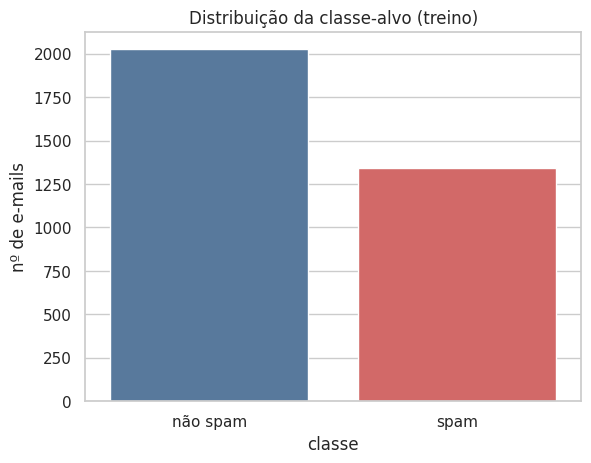

In [7]:
cnt = eda["classe"].value_counts()
print(cnt, "\n", (cnt / cnt.sum()).round(3))
ax = sns.barplot(x=cnt.index, y=cnt.values, palette=palette)
ax.set_ylabel("nº de e-mails"); ax.set_title("Distribuição da classe-alvo (treino)")
plt.show()

**Gráfico escolhido:** barras, por ser a forma mais direta de comparar contagens de categorias.

**Resposta:** No treino, **60,1% dos e-mails são não spam (2.025) e 39,9% são spam (1.343)**. O desbalanceamento é leve: a classe minoritária tem quase 40% dos exemplos, então **não aplicamos SMOTE nem pesos de classe**. Usamos divisão estratificada (39,9% de spam tanto no treino quanto no teste) e métricas além da acurácia, já que um modelo que respondesse "não spam" para tudo acertaria cerca de 60% sem aprender nada.

### Pergunta 2 — Quais atributos mais se associam a ser spam? *(relação entre variáveis)*

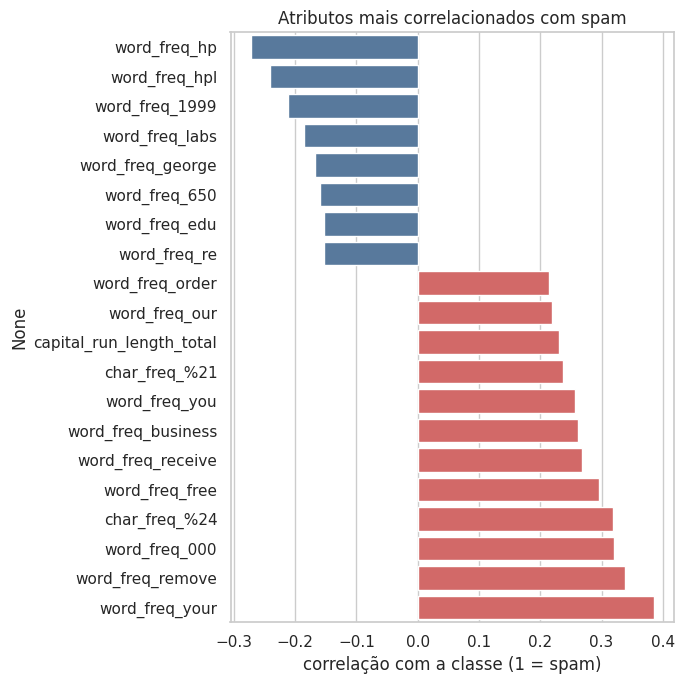

In [8]:
corr = train_df[feature_cols + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
top = pd.concat([corr.head(8), corr.tail(12)])
plt.figure(figsize=(7, 7))
sns.barplot(x=top.values, y=top.index, palette=["#4C78A8" if v < 0 else "#E45756" for v in top.values])
plt.xlabel("correlação com a classe (1 = spam)"); plt.title("Atributos mais correlacionados com spam")
plt.tight_layout(); plt.show()

**Gráfico escolhido:** barras horizontais ordenadas, que deixam o ranking legível mesmo com nomes longos.

**Resposta:** Os atributos com maior correlação **positiva** com spam são `word_freq_your` (≈ 0,39), `word_freq_remove` (≈ 0,34), `word_freq_000` e `char_freq_$` (≈ 0,32 cada) e `word_freq_free` (≈ 0,30). Os de maior correlação **negativa** são `word_freq_hp` (≈ −0,27), `word_freq_hpl` (≈ −0,24), `word_freq_1999` (≈ −0,21), `word_freq_labs` e `word_freq_george`. (No OpenML os símbolos aparecem codificados: `%21` é `!` e `%24` é `$`.)

As correlações são moderadas, nenhuma passa de 0,4 em módulo, então **nenhum atributo sozinho separa as classes**; é a combinação deles que ajuda. Palavras de apelo comercial (`your`, `remove`, `000`, `free`) e o símbolo `$` apontam para spam. Já `hp`, `hpl`, `labs` e `george` apontam para e-mail legítimo, o que reflete a caixa de e-mail de onde a base foi coletada (ver limitações em 2.10).

### Pergunta 3 — Palavras típicas de spam aparecem mais em spam do que em e-mails legítimos? *(comparação entre grupos)*

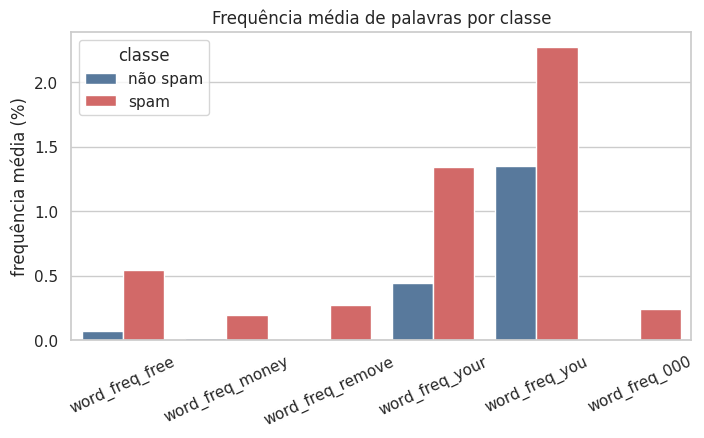

In [9]:
words = pick("word_freq_free", "word_freq_money", "word_freq_remove", "word_freq_your", "word_freq_you", "word_freq_000")
m = eda.groupby("classe")[words].mean().T.reset_index().melt(id_vars="index", var_name="classe", value_name="frequência média (%)")
plt.figure(figsize=(8, 4))
sns.barplot(data=m, x="index", y="frequência média (%)", hue="classe", palette=palette)
plt.xlabel(""); plt.xticks(rotation=25); plt.title("Frequência média de palavras por classe"); plt.show()

**Gráfico escolhido:** barras agrupadas, que permitem comparar duas classes lado a lado para cada palavra.

**Resposta:** Sim, e com diferença grande nas palavras de oferta. `free` aparece em média em ≈ 0,54% das palavras de um spam contra ≈ 0,07% nos legítimos (cerca de **8 vezes mais**). `money`, `remove` e `000` são praticamente ausentes nos e-mails legítimos (médias próximas de zero) e ficam entre ≈ 0,2% e ≈ 0,27% nos spams. `your` é cerca de **3 vezes** mais frequente em spam (≈ 1,3% contra ≈ 0,4%). Já `you` é mais frequente em spam, mas a diferença é menor (≈ 2,3% contra ≈ 1,35%), pois é uma palavra comum em qualquer e-mail. Ou seja, as maiores razões entre as classes estão nas palavras ligadas a dinheiro e oferta, não nas palavras gerais.

### Pergunta 4 — Spams usam mais letras maiúsculas? *(comparação entre grupos)*

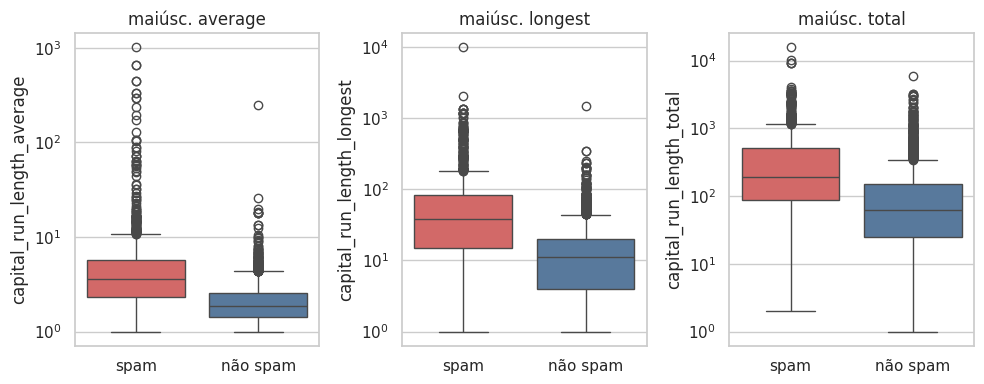

          capital_run_length_average  capital_run_length_longest  \
classe                                                             
não spam                       1.883                        11.0   
spam                           3.631                        38.0   

          capital_run_length_total  
classe                              
não spam                      63.0  
spam                         191.0  


In [10]:
plt.figure(figsize=(10, 4))
for i, c in enumerate(cap_cols, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(data=eda, x="classe", y=c, palette=palette)
    plt.yscale("log"); plt.xlabel(""); plt.title(c.replace("capital_run_length_", "maiúsc. "))
plt.tight_layout(); plt.show()
print(eda.groupby("classe")[cap_cols].median())

**Gráfico escolhido:** boxplot com eixo logarítmico, que resume mediana e dispersão por grupo e mostra os outliers, mesmo com valores que variam em várias ordens de grandeza.

**Resposta:** Sim. As **medianas dos spams são maiores nas três medidas**: média de maiúsculas 3,63 contra 1,88 (≈ 1,9 vez), maior sequência 38 contra 11 (≈ 3,5 vezes) e total 191 contra 63 (≈ 3 vezes). No gráfico, a caixa do spam fica deslocada para cima nas três variáveis, mas **as caixas se sobrepõem parcialmente** (principalmente em `average`) e há muitos outliers nas duas classes. Os valores mais extremos, por exemplo média acima de 100, são em sua maioria de spam. Conclusão: o uso de maiúsculas é um bom sinal, mas não separa as classes sozinho.

### Pergunta 5 — Os símbolos `!` e `$` estão ligados a spam? *(associação)*

,símbolo,% de spam entre e-mails COM o símbolo,% de spam entre e-mails SEM o símbolo,% dos e-mails com o símbolo
0,!,65.4,13.4,50.9
1,$,78.2,23.1,30.4


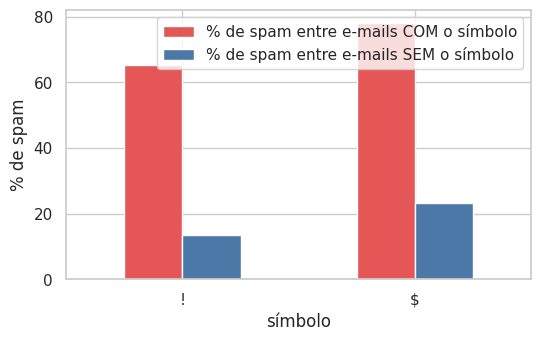

In [12]:
sym = pick("char_freq_%21", "char_freq_%24")
res = []
for c in sym:
    tem = eda[c] > 0
    # Traduz o código URL-encoded para o símbolo real na visualização
    nome_amigavel = c.replace("char_freq_", "").replace("%21", "!").replace("%24", "$")
    res.append({"símbolo": nome_amigavel,
                "% de spam entre e-mails COM o símbolo": round(100 * eda.loc[tem, TARGET].mean(), 1),
                "% de spam entre e-mails SEM o símbolo": round(100 * eda.loc[~tem, TARGET].mean(), 1),
                "% dos e-mails com o símbolo": round(100 * tem.mean(), 1)})
res = pd.DataFrame(res); display(res)
res.set_index("símbolo")[["% de spam entre e-mails COM o símbolo", "% de spam entre e-mails SEM o símbolo"]].plot.bar(
    rot=0, color=["#E45756", "#4C78A8"], figsize=(6, 3.5)); plt.ylabel("% de spam"); plt.show()

**Gráfico escolhido:** barras comparando a taxa de spam com e sem o símbolo, o que traduz "associação" em algo fácil de interpretar.

**Resposta:** Sim, ambos aumentam bastante a chance de spam, tomando como referência os 39,9% de spam da base:

- **`!`** aparece em 50,9% dos e-mails. Entre os que têm `!`, **65,4% são spam**; entre os que não têm, apenas 13,4% (≈ 4,9 vezes mais).
- **`$`** aparece em 30,4% dos e-mails. Entre os que têm `$`, **78,2% são spam**; entre os que não têm, 23,1% (≈ 3,4 vezes mais).

O `$` é o sinal mais forte quando aparece, e o `!` é o mais comum. Nenhum dos dois é conclusivo sozinho: 21,8% dos e-mails com `$` e 34,6% dos com `!` são legítimos.

### Pergunta 6 — Quais atributos são redundantes entre si (multicolinearidade)? *(relação entre variáveis)*

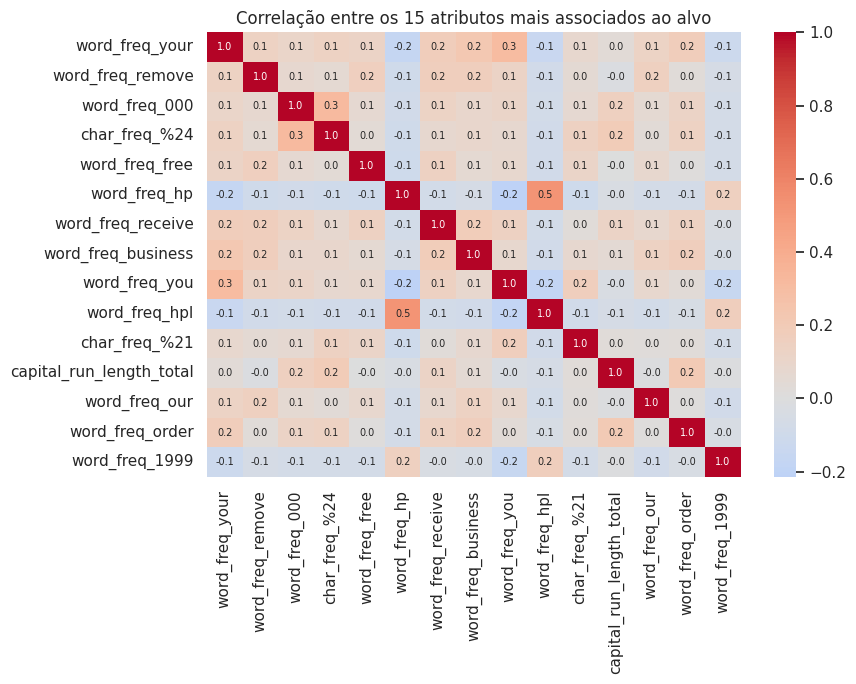

Pares com |correlação| > 0.7:
word_freq_857  word_freq_415       0.993923
               word_freq_direct    0.837140
word_freq_415  word_freq_direct    0.833093
dtype: float64


In [13]:
top_feats = train_df[feature_cols].corrwith(train_df[TARGET]).abs().sort_values(ascending=False).head(15).index
plt.figure(figsize=(9, 7))
sns.heatmap(train_df[top_feats].corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlação entre os 15 atributos mais associados ao alvo"); plt.tight_layout(); plt.show()

c = train_df[feature_cols].corr().abs().where(np.triu(np.ones((len(feature_cols),)*2), 1).astype(bool)).stack()
print("Pares com |correlação| > 0.7:"); print(c[c > 0.7].sort_values(ascending=False).head(10))

**Gráfico escolhido:** mapa de calor (heatmap), que mostra de uma só vez a matriz de correlações.

**Resposta:** Os pares com correlação absoluta acima de 0,7 são `word_freq_857` e `word_freq_415` (**0,99**, praticamente a mesma informação, provavelmente códigos de área de telefone que aparecem juntos nos mesmos e-mails), e ambos com `word_freq_direct` (≈ 0,83). Entre os 15 atributos mais associados ao alvo a redundância é baixa: quase todas as correlações ficam abaixo de 0,3 em módulo, com exceção de `hp`–`hpl` (0,5) e `your`–`you` (≈ 0,3).

Para a **regressão logística** isso importa, porque atributos redundantes deixam os coeficientes instáveis (a regularização L2, usada por padrão, ameniza). Para **árvores e Random Forest** o efeito é pequeno, mas a redundância divide a importância entre os atributos correlacionados, o que veremos na importância por permutação.

### Pergunta 7 — As variáveis são esparsas e assimétricas? Isso exige transformação?

Mediana do percentual de zeros por atributo: 84.0%
Atributos com mais de 90% de zeros: 19 de 57


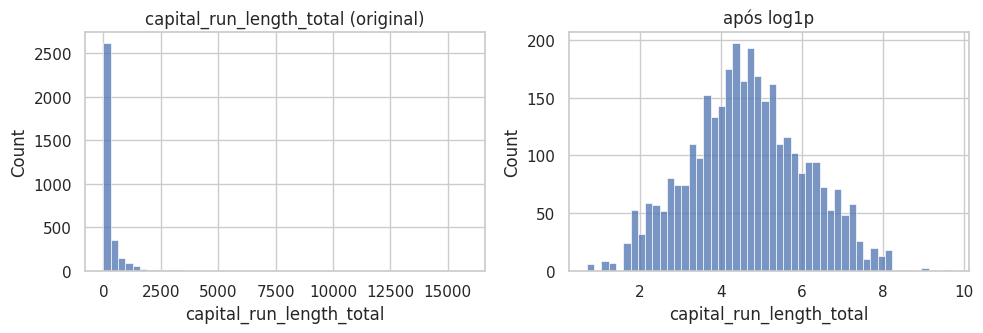

word_freq_3d                  34.075204
char_freq_%23                 32.931985
capital_run_length_longest    32.088658
word_freq_parts               24.735854
char_freq_%5B                 22.699268
dtype: float64


In [14]:
zero_pct = (train_df[feature_cols] == 0).mean().sort_values(ascending=False)
print(f"Mediana do percentual de zeros por atributo: {100 * zero_pct.median():.1f}%")
print(f"Atributos com mais de 90% de zeros: {(zero_pct > .9).sum()} de {len(feature_cols)}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(train_df["capital_run_length_total"], bins=50, ax=ax[0]); ax[0].set_title("capital_run_length_total (original)")
sns.histplot(np.log1p(train_df["capital_run_length_total"]), bins=50, ax=ax[1]); ax[1].set_title("após log1p")
plt.tight_layout(); plt.show()
skew = train_df[feature_cols].skew().sort_values(ascending=False); print(skew.head(5))

**Gráfico escolhido:** histogramas antes/depois da transformação, que mostram diretamente o efeito do `log1p` sobre a assimetria.

**Resposta:** Sim, as variáveis são **muito esparsas e assimétricas**. A mediana do percentual de zeros por atributo é **84,0%** e **19 dos 57 atributos têm mais de 90% de zeros**. As assimetrias (*skewness*) mais altas são `word_freq_3d` (≈ 34), `char_freq_#` (≈ 33) e `capital_run_length_longest` (≈ 32), valores muito acima de 1, que já indica forte cauda à direita.

O histograma mostra o efeito do `log1p`: em `capital_run_length_total`, os dados originais ficam concentrados perto de zero com cauda até ≈ 16 mil; depois da transformação, a distribuição vira um sino, bem mais simétrico. Isso **justifica `log1p` + `StandardScaler`** para regressão logística, KNN, SVM e rede neural, que são sensíveis a escala e distância. Árvores e Random Forest dispensam a transformação, pois só dependem da ordem dos valores.

### Pergunta 8 — O comprimento total de maiúsculas separa bem as classes? *(relação entre variáveis)*

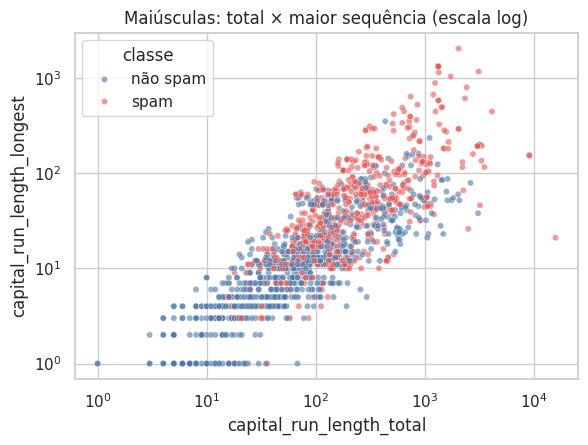

In [15]:
plt.figure(figsize=(6.5, 4.5))
sns.scatterplot(data=eda.sample(min(1500, len(eda)), random_state=RANDOM_STATE),
                x="capital_run_length_total", y="capital_run_length_longest", hue="classe", palette=palette, alpha=.6, s=20)
plt.xscale("log"); plt.yscale("log"); plt.title("Maiúsculas: total × maior sequência (escala log)"); plt.show()

**Gráfico escolhido:** dispersão, apropriada para ver a relação entre duas variáveis numéricas e como as classes se agrupam no plano.

**Resposta:** Há **separação parcial, com muita sobreposição**. Os spams (vermelho) se concentram na parte superior direita do gráfico, com total acima de ≈ 100 e maior sequência acima de ≈ 30. Os não spams (azul) ocupam também a região inferior esquerda, com valores pequenos e discretos, e na faixa intermediária (total entre 10² e 10³) as duas nuvens se misturam. As duas variáveis crescem juntas, como esperado, pois uma sequência longa aumenta o total. Portanto, o uso de maiúsculas ajuda, mas **só com estas duas variáveis não dá para classificar bem**; é preciso combinar com as palavras e símbolos.

### Pergunta 9 — Quais atributos quase nunca aparecem e podem ter pouca utilidade?

In [16]:
print(zero_pct.head(10).round(3))
print(f"\nAtributos presentes em menos de 5% dos e-mails: {(1 - zero_pct < .05).sum()}")

word_freq_3d            0.990
word_freq_table         0.987
word_freq_parts         0.981
word_freq_font          0.973
word_freq_cs            0.967
word_freq_conference    0.953
word_freq_857           0.953
word_freq_415           0.950
word_freq_telnet        0.932
word_freq_addresses     0.927
dtype: float64

Atributos presentes em menos de 5% dos e-mails: 8


**Resposta:** Sim, existem atributos muito raros: `word_freq_3d` (99,0% de zeros), `table` (98,7%), `parts` (98,1%), `font` (97,3%), `cs` (96,7%) e `conference` (95,3%). Ao todo, **8 atributos aparecem em menos de 5% dos e-mails**. Decidimos **manter todos**, por três motivos: com 57 atributos não há custo computacional relevante; um atributo raro pode ser muito informativo quando aparece; e os modelos lidam bem com isso (árvores ignoram divisões inúteis, a regressão logística com L2 reduz os pesos e o Random Forest sorteia subconjuntos de atributos). Além disso, filtrar atributos olhando o alvo fora da validação causaria vazamento de dados.

### 2.10 Síntese da EDA e limitações da base

1. **Balanceamento:** 39,9% spam e 60,1% não spam, leve desbalanceamento; usamos estratificação e métricas além da acurácia.
2. **Sinais mais fortes:** palavras de oferta e dinheiro (`your`, `remove`, `000`, `free`, `money`), o símbolo `$` (78,2% de spam quando presente) e o `!` (65,4%), além de mais maiúsculas (mediana do total de 191 contra 63). Em sentido contrário, `hp`, `hpl`, `1999`, `labs` e `george` indicam e-mail legítimo. Nenhum sinal isolado é suficiente (correlações abaixo de 0,4).
3. **Distribuição:** atributos muito esparsos (mediana de 84% de zeros; 19 atributos com mais de 90%) e assimétricos, com outliers nas variáveis de maiúsculas (4% a 7% do treino, dos quais 75% a 90% são spam). Mantivemos os outliers e usamos `log1p` + escalonamento nos modelos sensíveis à escala.
4. **Redundância:** baixa, exceto `857`/`415`/`direct` (correlação de até 0,99) e `hp`/`hpl` (0,5).
5. **Qualidade:** sem valores faltantes, mas com **391 linhas duplicadas (8,5%)**, removidas antes da divisão treino/teste.

**Limitações da base:**
- Os dados são de **1998–1999** e vieram de uma caixa de e-mail específica da HP Labs. Palavras como `george` e `hp` são indicadoras de e-mail *legítimo* **apenas porque pertenciam ao dono daquela caixa**: o modelo pode não generalizar para outros usuários ou para o spam atual.
- Os atributos já são **contagens pré-extraídas** (bag-of-words de 48 palavras), sem o texto original, o que impede explorar outros recursos (ordem das palavras, links, remetente).
- O spam evoluiu: técnicas atuais (imagens, textos gerados) não estão representadas.

## 3. Modelagem

### 3.1 Tarefa e variável-alvo
Classificação binária; alvo `class` (1 = spam). O custo dos erros é **assimétrico**: classificar um e-mail legítimo como spam (falso positivo) costuma ser pior do que deixar um spam passar (falso negativo), pois o usuário pode perder uma mensagem importante.

### 3.2 Separação treino/teste e controle de vazamento
- A separação (80% treino / 20% teste, estratificada pela classe, `random_state=42`) foi feita na seção 1.3, **antes de qualquer transformação**. As 391 duplicatas (8,5% da base) foram removidas antes da divisão, para que a mesma linha não caia nos dois conjuntos. Resultado: 3.368 e-mails de treino e 842 de teste, com 39,9% de spam em ambos.
- Todas as transformações (`log1p`, escalonamento) ficam **dentro de `Pipeline`**, de modo que, na validação cruzada, são aprendidas apenas com as dobras de treino.
- O conjunto de teste só é usado **uma vez**, no final, para a avaliação. Escolha de modelo e de limiar usam apenas validação cruzada no treino.

### 3.3 Validação, transformações e métricas
- **Validação:** `StratifiedKFold` com 5 dobras, mantendo a proporção de spam em cada uma.
- **Transformações:** `log1p` + `StandardScaler` para regressão logística, KNN, SVM e MLP (sensíveis a escala/assimetria). Árvore, Random Forest e Naive Bayes usam os dados originais (o Naive Bayes multinomial exige valores não negativos).
- **Balanceamento:** não aplicado, pois o desbalanceamento é leve; usamos estratificação.
- **Métricas:** **precisão** (de tudo que marcamos como spam, quanto era spam — ligada ao custo do falso positivo), **recall**, **F1**, **ROC-AUC** e **PR-AUC** (*average precision*, independente do limiar). A acurácia é reportada, mas não é a métrica principal.
- **Busca de hiperparâmetros:** `GridSearchCV` com grades pequenas, otimizando **PR-AUC**.

In [17]:
FEATURES, TARGET_COL = feature_cols, TARGET
X_train, y_train = train_df[FEATURES], train_df[TARGET_COL]
X_test,  y_test  = test_df[FEATURES],  test_df[TARGET_COL]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
log1p = lambda: FunctionTransformer(np.log1p, feature_names_out="one-to-one")

models = {
  # --- baseline simples ---
  "Regressão Logística (baseline)": (
      Pipeline([("log", log1p()), ("sc", StandardScaler()),
                ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))]),
      {"clf__C": [0.01, 0.1, 1, 10]}),
  "Árvore de Decisão": (
      DecisionTreeClassifier(random_state=RANDOM_STATE),
      {"max_depth": [3, 5, 8, 12, None], "min_samples_leaf": [1, 5, 20]}),
  "KNN": (
      Pipeline([("log", log1p()), ("sc", StandardScaler()), ("clf", KNeighborsClassifier())]),
      {"clf__n_neighbors": [3, 5, 11, 21], "clf__weights": ["uniform", "distance"]}),
  "SVM (RBF)": (
      Pipeline([("log", log1p()), ("sc", StandardScaler()),
                ("clf", SVC(probability=True, random_state=RANDOM_STATE))]),
      {"clf__C": [0.5, 1, 5, 10], "clf__gamma": ["scale", 0.01]}),
  "Random Forest": (
      RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
      {"n_estimators": [200, 400], "max_depth": [None, 20], "min_samples_leaf": [1, 2]}),
  "Rede Neural (MLP)": (
      Pipeline([("log", log1p()), ("sc", StandardScaler()),
                ("clf", MLPClassifier(max_iter=500, early_stopping=True, random_state=RANDOM_STATE))]),
      {"clf__hidden_layer_sizes": [(32,), (64, 32)], "clf__alpha": [1e-4, 1e-2]}),
  # --- técnica extra (não vista em sala) ---
  "Naive Bayes (extra)": (
      MultinomialNB(),
      {"alpha": [0.01, 0.1, 0.5, 1.0]}),
}

fitted, cv_scores = {}, {}
for name, (est, grid) in models.items():
    t0 = time.time()
    gs = GridSearchCV(est, grid, scoring="average_precision", cv=cv, n_jobs=-1).fit(X_train, y_train)
    fitted[name], cv_scores[name] = gs.best_estimator_, gs.best_score_
    print(f"{name:32s} PR-AUC (CV) = {gs.best_score_:.4f} | {gs.best_params_} | {time.time()-t0:.0f}s")

Regressão Logística (baseline)   PR-AUC (CV) = 0.9672 | {'clf__C': 0.1} | 3s
Árvore de Decisão                PR-AUC (CV) = 0.9181 | {'max_depth': 12, 'min_samples_leaf': 20} | 3s
KNN                              PR-AUC (CV) = 0.9655 | {'clf__n_neighbors': 21, 'clf__weights': 'distance'} | 1s
SVM (RBF)                        PR-AUC (CV) = 0.9716 | {'clf__C': 10, 'clf__gamma': 0.01} | 40s
Random Forest                    PR-AUC (CV) = 0.9770 | {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 400} | 73s
Rede Neural (MLP)                PR-AUC (CV) = 0.9713 | {'clf__alpha': 0.01, 'clf__hidden_layer_sizes': (64, 32)} | 9s
Naive Bayes (extra)              PR-AUC (CV) = 0.7886 | {'alpha': 0.01} | 0s


## 4. Resultados

### 4.1 Comparação entre os modelos (conjunto de teste, limiar padrão 0,5)

In [18]:
def metrics(y, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {"Acurácia": accuracy_score(y, pred), "Precisão": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "ROC-AUC": roc_auc_score(y, proba), "PR-AUC": average_precision_score(y, proba)}

test_proba = {n: m.predict_proba(X_test)[:, 1] for n, m in fitted.items()}
results = pd.DataFrame({n: metrics(y_test, p) for n, p in test_proba.items()}).T
results.insert(0, "PR-AUC (CV treino)", pd.Series(cv_scores))
results = results.sort_values("PR-AUC", ascending=False)
results.round(4)

,PR-AUC (CV treino),Acurácia,Precisão,Recall,F1,ROC-AUC,PR-AUC
Random Forest,0.9770,0.9371,0.9408,0.8988,0.9193,0.9870,0.9809
Rede Neural (MLP),0.9713,0.9489,0.9347,0.9375,0.9361,0.9854,0.9756
KNN,0.9655,0.9323,0.9292,0.8988,0.9138,0.9828,0.9719
Regressão Logística (baseline),0.9672,0.9382,0.9329,0.9107,0.9217,0.9809,0.9683
SVM (RBF),0.9716,0.9489,0.9322,0.9405,0.9363,0.9805,0.9556
Árvore de Decisão,0.9181,0.8955,0.8758,0.8601,0.8679,0.9614,0.9360
Naive Bayes (extra),0.7886,0.7886,0.7616,0.6845,0.7210,0.8360,0.7690


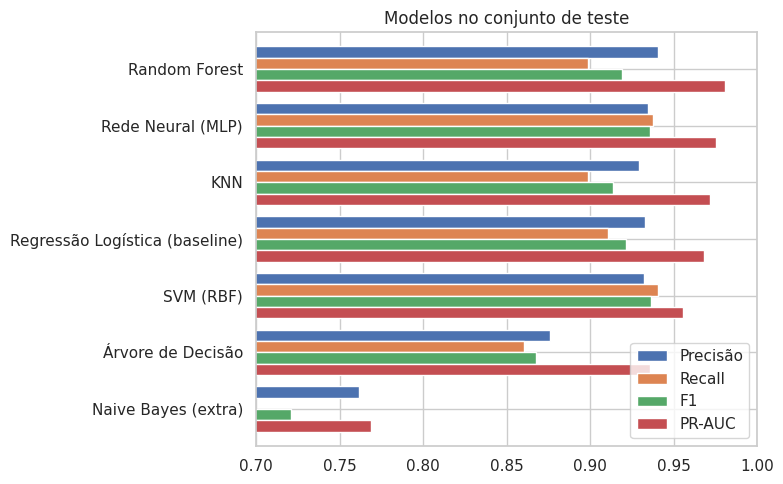

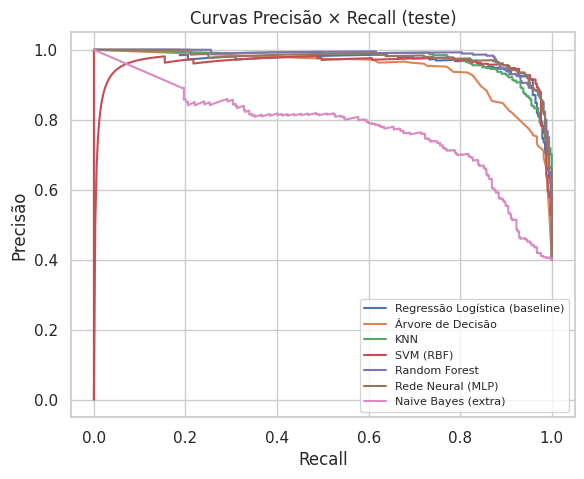

In [19]:
results[["Precisão", "Recall", "F1", "PR-AUC"]].plot.barh(figsize=(8, 5), width=.8)
plt.xlim(.7, 1.0); plt.title("Modelos no conjunto de teste"); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

plt.figure(figsize=(6.5, 5))
for n, p in test_proba.items():
    pr, rc, _ = precision_recall_curve(y_test, p); plt.plot(rc, pr, label=n)
plt.xlabel("Recall"); plt.ylabel("Precisão"); plt.title("Curvas Precisão × Recall (teste)")
plt.legend(fontsize=8); plt.show()

### 4.2 Técnica extra: ajuste do limiar de decisão
O limiar padrão (0,5) trata os dois erros como igualmente graves. Como falso positivo é mais custoso, escolhemos o limiar que maximiza o **F0,5** (que pesa a precisão mais que o recall). O limiar é escolhido **apenas com previsões fora-da-dobra do treino** (`cross_val_predict`), sem tocar no teste.

Melhor modelo (CV): Random Forest
Limiar escolhido (F0,5 no treino): 0.626


,Acurácia,Precisão,Recall,F1,ROC-AUC,PR-AUC
"limiar 0,5",0.9371,0.9408,0.8988,0.9193,0.987,0.9809
limiar 0.63,0.9418,0.9799,0.8720,0.9228,0.987,0.9809


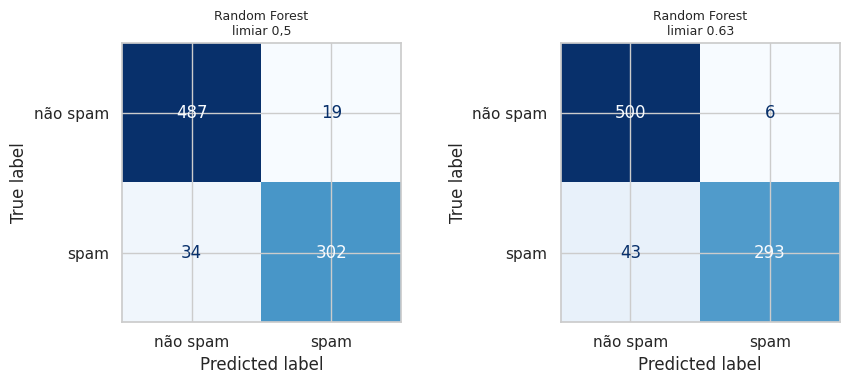

In [20]:
best_name = max(cv_scores, key=cv_scores.get)      # melhor modelo escolhido pelo CV, não pelo teste
best = fitted[best_name]
print("Melhor modelo (CV):", best_name)

oof = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
b2 = 0.5 ** 2
with np.errstate(divide="ignore", invalid="ignore"):
    f05 = np.nan_to_num((1 + b2) * prec * rec / (b2 * prec + rec))
thr_opt = float(thr[np.argmax(f05[:-1])])
print(f"Limiar escolhido (F0,5 no treino): {thr_opt:.3f}")

cmp = pd.DataFrame({"limiar 0,5": metrics(y_test, test_proba[best_name], 0.5),
                    f"limiar {thr_opt:.2f}": metrics(y_test, test_proba[best_name], thr_opt)}).T
display(cmp.round(4))

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, t, ttl in zip(ax, (0.5, thr_opt), ("limiar 0,5", f"limiar {thr_opt:.2f}")):
    ConfusionMatrixDisplay.from_predictions(y_test, (test_proba[best_name] >= t).astype(int), ax=a,
        display_labels=["não spam", "spam"], colorbar=False, cmap="Blues"); a.set_title(f"{best_name}\n{ttl}", fontsize=9)
plt.tight_layout(); plt.show()

### 4.3 Técnica extra: importância por permutação
Quais atributos mais pesam nas decisões do melhor modelo? Embaralhamos cada atributo no teste e medimos a queda do PR-AUC.

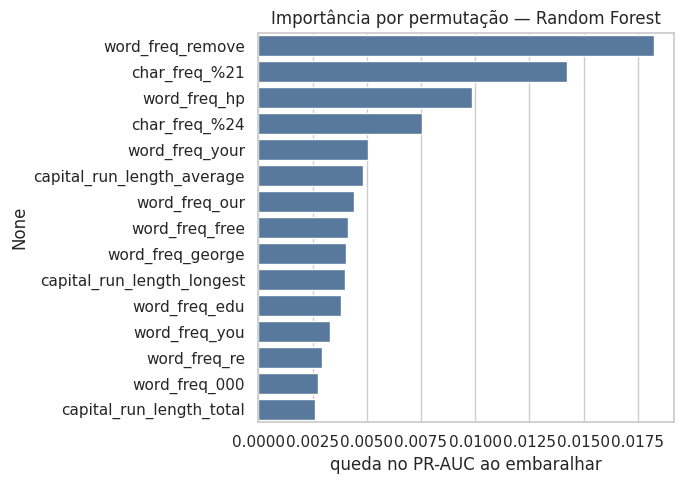

In [21]:
pi = permutation_importance(best, X_test, y_test, scoring="average_precision", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False).head(15)
plt.figure(figsize=(7, 5)); sns.barplot(x=imp.values, y=imp.index, color="#4C78A8")
plt.xlabel("queda no PR-AUC ao embaralhar"); plt.title(f"Importância por permutação — {best_name}"); plt.tight_layout(); plt.show()

### 4.4 Interpretação no contexto do problema

- **Quem foi melhor e por quê:** o **Random Forest** teve o melhor PR-AUC na validação cruzada (0,977) e no teste (0,981; ROC-AUC 0,987), além da maior precisão (0,941). **SVM e rede neural** tiveram o maior recall (0,941 e 0,938), o maior F1 (0,936) e a maior acurácia (0,949). O baseline de regressão logística já é forte (PR-AUC 0,968; F1 0,922), o que indica que a relação é em boa parte linear depois do `log1p`; o Random Forest o supera em ≈ 1,3 ponto de PR-AUC. As diferenças entre os cinco melhores são pequenas: o teste tem 842 e-mails (336 spams), e cada spam a mais ou a menos muda o recall em ≈ 0,3 ponto, então não dá para afirmar com segurança qual é o melhor entre eles.
- **O que significam as métricas aqui:** com o limiar padrão (0,5), o Random Forest marcou 321 e-mails como spam, dos quais 19 eram legítimos (≈ 6 em cada 100), e deixou passar 34 spams. Com o **limiar ajustado (0,63)**, a precisão sobe de 0,941 para **0,980** (só 6 legítimos bloqueados em 299 e-mails marcados, ≈ 2 em cada 100), ao custo de recall de 0,899 para 0,872 (43 spams passam, 9 a mais). Em troca, a acurácia sobe de 0,937 para 0,942 e o F1 de 0,919 para 0,923. É a troca que queríamos: **13 e-mails legítimos a menos perdidos** contra 9 spams a mais na caixa de entrada.
- **Modelos mais simples vs. complexos:** a regressão logística treina em segundos e seus coeficientes são interpretáveis; o Random Forest e o SVM levaram de 40 a 73 s na busca de hiperparâmetros para ganhar ≈ 1 a 2 pontos de PR-AUC e de recall. Uma árvore de decisão isolada ficou bem pior (F1 0,868), por ser instável, e o Random Forest corrige isso ao combinar várias árvores. Em um filtro real, com milhares de e-mails por dia, um ganho de 1 ponto pode valer o custo; num protótipo, o baseline já resolveria bem.
- **Naive Bayes:** foi o pior modelo por larga margem (F1 0,721, recall 0,685, PR-AUC 0,769). Provavelmente porque a suposição de independência não vale (palavras como `hp` e `hpl`, `857` e `415` aparecem juntas) e porque o Naive Bayes multinomial espera contagens, enquanto nossos atributos são percentuais e comprimentos contínuos. Foi útil como técnica extra para comparação, mas não é adequado a esta representação.
- **Atributos mais importantes:** pela importância por permutação no Random Forest, os cinco principais são `word_freq_remove`, `char_freq_!`, `word_freq_hp`, `char_freq_$` e `word_freq_your`. Isso confirma boa parte da EDA (`remove`, `$`, `your` e `!` estavam entre os sinais mais fortes), mas há diferenças: `your` teve a maior correlação e aparece só em quinto, porque a importância mede a contribuição ao modelo e divide o crédito entre atributos correlacionados. A queda no PR-AUC por atributo é pequena (no máximo ≈ 0,018), o que mostra que o modelo usa muitos sinais redundantes e não depende de um único. `hp`, `george`, `edu` e `re` também aparecem entre os 15 primeiros, e esses são sinais específicos da caixa de e-mail de origem (ver limitações).

### 4.5 Limitações e possíveis melhorias
- **Generalização:** a base é antiga (1998–1999) e vem de uma única caixa de e-mail; atributos como `george` e `hp` são específicos do dono original e aparecem entre os mais importantes do modelo. Em produção seria preciso retreinar com dados atuais.
- **Teste único e pequeno:** a avaliação final usa uma só divisão, de 842 e-mails, sem intervalo de confiança; as diferenças entre os melhores modelos (poucos e-mails) estão dentro do ruído esperado. Repetir a divisão com várias sementes ou usar validação cruzada repetida daria uma comparação mais robusta.
- **Validação:** a busca de hiperparâmetros e o PR-AUC de CV reportado usam as mesmas dobras (levemente otimista); uma validação aninhada seria mais rigorosa.
- **Custo dos erros:** o limiar foi otimizado por F0,5, uma escolha subjetiva; o ideal seria usar o custo real de um falso positivo e de um falso negativo.
- **Melhorias:** Gradient Boosting, busca de hiperparâmetros mais ampla, engenharia de atributos sobre o texto original (TF-IDF, n-gramas) e calibração de probabilidades.